In [1]:
import pandas as pd
import numpy as np
import scipy
import matplotlib.pyplot as plt
import seaborn as sns

print("Allt fungerar!")

Allt fungerar!


In [3]:
import os

for root, dirs, files in os.walk("../data/raw"):
    print(root)
    for f in files:
        print("   ", f)

../data/raw
    .gitkeep
../data/raw/archive
    gamer5-ppg-2000-01-01.csv
    gamer1-annotations.csv
    gamer5-ppg-2000-01-02.csv
    gamer3-ppg-2000-01-02.csv
    gamer3-ppg-2000-01-01.csv
    gamer2-ppg-2000-01-02.csv
    gamer5-annotations.csv
    gamer2-ppg-2000-01-01.csv
    gamer1-ppg-2000-01-01.csv
    gamer2-annotations.csv
    gamer1-ppg-2000-01-02.csv
    gamer3-annotations.csv
    gamer4-ppg-2000-01-01.csv
    gamer4-annotations.csv
    gamer4-ppg-2000-01-02.csv


In [4]:
ppg = pd.read_csv("../data/raw/archive/gamer1-ppg-2000-01-01.csv", nrows=100000)
ppg.head()

,Time,Red_Signal
0,12:54:40.369052,705
1,12:54:40.369900,559
2,12:54:40.369900,438
3,12:54:40.370917,334
4,12:54:40.370917,254


In [5]:
import pandas as pd
import matplotlib.pyplot as plt

ppg = pd.read_csv("../data/raw/archive/gamer1-ppg-2000-01-01.csv", nrows=100000)

# Gör om texten till en riktig tidsstämpel
ppg["Time"] = pd.to_datetime(ppg["Time"], format="%H:%M:%S.%f")

# Sekunder sedan start
ppg["t_sec"] = (ppg["Time"] - ppg["Time"].iloc[0]).dt.total_seconds()
ppg.head()

,Time,Red_Signal,t_sec
0,1900-01-01 12:54:40.369052,705,0.000000
1,1900-01-01 12:54:40.369900,559,0.000848
2,1900-01-01 12:54:40.369900,438,0.000848
3,1900-01-01 12:54:40.370917,334,0.001865
4,1900-01-01 12:54:40.370917,254,0.001865


In [6]:
ppg.info()
print("Saknade värden:", ppg["Red_Signal"].isna().sum())
print("Duplicerade tidsstämplar:", ppg["Time"].duplicated().sum())

duration = ppg["t_sec"].iloc[-1]
print("Ungefärlig sampelfrekvens (Hz):", len(ppg) / duration)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   Time        100000 non-null  datetime64[us]
 1   Red_Signal  100000 non-null  int64         
 2   t_sec       100000 non-null  float64       
dtypes: datetime64[us](1), float64(1), int64(1)
memory usage: 2.3 MB
Saknade värden: 0
Duplicerade tidsstämplar: 15316
Ungefärlig sampelfrekvens (Hz): 100.75921910379962


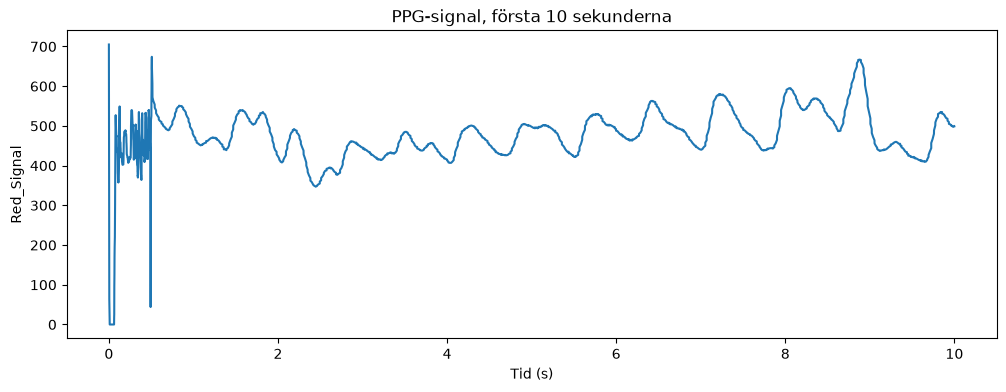

In [7]:
subset = ppg[ppg["t_sec"] <= 10]

plt.figure(figsize=(12, 4))
plt.plot(subset["t_sec"], subset["Red_Signal"])
plt.xlabel("Tid (s)")
plt.ylabel("Red_Signal")
plt.title("PPG-signal, första 10 sekunderna")
plt.show()